# 07 — Datos externos: HUPA-UCM frente a OhioT1DM

**Objetivo**: caracterizar HUPA-UCM como conjunto de **validación externa**  y fijar el split **antes** de evaluar ningún modelo. Tres
preguntas:

1. ¿Qué hay de verdad en los ficheros, y qué parte del preprocesado de los autores se puede usar?
2. ¿En qué se parece HUPA a OhioT1DM y en qué no? (población, sensor, tratamiento, entradas)
3. ¿Cuántos eventos de hipoglucemia hay para evaluar, y con qué potencia?

**Fuente**: Hidalgo et al. (2024), *Data in Brief* 55:110559; Mendeley Data,
doi:10.17632/3hbcscwz44.1, licencia CC BY-NC-ND 4.0. 25 personas con DT1 del Hospital
Universitario Príncipe de Asturias, FreeStyle Libre 2 (lectura cada 15 min) y Fitbit Ionic.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tfm.data import hupa
from tfm.data import quality as q
from tfm.data.features import FEATURE_COLUMNS
from tfm.data.loaders import load_cgm, load_processed
from tfm.data.parser import PATIENTS as OHIO_PATIENTS
from tfm.viz import CATEGORICAL, FIG_WIDTH_FULL, INK, ROLE, add_glycemic_bands, save_figure, set_style

set_style()
pd.set_option("display.width", 160)

# OhioT1DM is the reference cohort; HUPA the one under study. Partial and missing
# treatment records are drawn as one colour: four colours fail the all-pairs check.
OHIO_COLOR = ROLE["referencia"]
HUPA_COLOR = ROLE["modelo"]
TIER_COLORS = {"completo": ROLE["modelo"], "parcial": CATEGORICAL[1],
               "sin_registro": CATEGORICAL[1]}

frames = hupa.load_frames()
summary = hupa.load_summary()
print(f"Pacientes HUPA construidos: {len(frames)}  (excluidos: {', '.join(hupa.EXCLUDED)})")

Pacientes HUPA construidos: 23  (excluidos: HUPA0009P, HUPA0010P)


## 1. La cohorte HUPA-UCM

In [2]:
cols = ["patient", "treatment", "record_tier", "days", "n_readings", "n_segments",
        "median_segment_h", "pct_readings_70_180", "pct_readings_below_70", "hypo_events"]
summary[cols]

,patient,treatment,record_tier,days,n_readings,n_segments,median_segment_h,pct_readings_70_180,pct_readings_below_70,hypo_events
0,HUPA0001P,CSII,completo,13.9,1325,1,333.4,54.19,2.19,6
1,HUPA0002P,CSII,completo,11.0,1047,2,131.5,61.22,23.88,25
2,HUPA0003P,CSII,completo,13.1,1251,1,314.1,68.19,7.03,18
3,HUPA0004P,CSII,completo,11.0,903,9,22.1,47.84,11.52,13
4,HUPA0005P,CSII,completo,13.3,1274,1,320.1,71.82,3.61,14
5,HUPA0006P,CSII,completo,7.9,727,6,12.6,56.81,9.22,11
6,HUPA0007P,CSII,completo,13.3,1277,1,320.4,46.20,8.85,15
7,HUPA0011P,CSII,parcial,13.3,1277,1,319.7,65.62,2.51,6
8,HUPA0014P,MDI,parcial,13.3,1074,11,17.3,45.16,4.56,8
9,HUPA0015P,MDI,sin_registro,13.2,1221,7,22.2,58.07,4.59,13


In [3]:
agg = summary.groupby(["record_tier", "treatment"]).agg(
    pacientes=("patient", "size"), dias=("days", "sum"),
    lecturas=("n_readings", "sum"), eventos=("hypo_events", "sum"))
print(agg)
print(f"\nTotal: {summary.n_readings.sum():,} lecturas reales en {summary.days.sum():.0f} días; "
      f"{summary.hypo_events.sum()} eventos de hipoglucemia")
print(pd.Series(hupa.EXCLUDED, name="motivo de exclusión").to_string())

                        pacientes   dias  lecturas  eventos
record_tier  treatment                                     
completo     CSII              10  124.3     11512      181
             MDI                6  817.0     71795      728
parcial      CSII               1   13.3      1277        6
             MDI                4   44.2      4029       36
sin_registro CSII               1   13.5      1272       22
             MDI                1   13.2      1221       13

Total: 91,106 lecturas reales en 1026 días; 986 eventos de hipoglucemia
HUPA0009P    sin lecturas del Libre (fichero vacío)
HUPA0010P         sin lecturas históricas del Libre


Quedan **23 pacientes**: HUPA0009P y HUPA0010P se excluyen porque no tienen lecturas del Libre
(su glucosa preprocesada sale del sensor Enlite de la bomba Medtronic). La duración es muy
desigual: **20 pacientes de 8 a 14 días y 3 de 66, 141 y 574 días**, los tres con plumas (MDI).
Esos tres concentran **699 de los 986 eventos**, y HUPA0027P sola, 549. Cualquier agregado por
muestras o por eventos que no los separe estará dominado por un paciente, así que los largos
se informan aparte.

In [4]:
summary[["patient", "treatment", "record_tier", "basal_u_per_day", "bolus_u_per_day",
         "carbs_g_per_day", "pct_pump_suspended", "pct_sensor_jump"]]

,patient,treatment,record_tier,basal_u_per_day,bolus_u_per_day,carbs_g_per_day,pct_pump_suspended,pct_sensor_jump
0,HUPA0001P,CSII,completo,14.2,10.9,85.0,6.45,0.07
1,HUPA0002P,CSII,completo,25.4,20.4,57.7,0.38,0.00
2,HUPA0003P,CSII,completo,15.7,20.5,331.7,2.15,0.08
3,HUPA0004P,CSII,completo,21.1,43.0,182.9,1.63,0.00
4,HUPA0005P,CSII,completo,19.1,7.6,66.4,0.94,0.00
5,HUPA0006P,CSII,completo,21.7,28.6,275.2,0.00,0.00
6,HUPA0007P,CSII,completo,23.2,35.3,206.4,5.25,0.00
7,HUPA0011P,CSII,parcial,0.0,0.0,84.5,0.00,0.00
8,HUPA0014P,MDI,parcial,0.0,20.5,135.9,0.00,0.13
9,HUPA0015P,MDI,sin_registro,0.0,0.0,0.0,0.00,0.00


Con las unidades corregidas (basal ×12 → U/h; hidratos ×10 salvo en los cuatro pacientes que
ya los registraban en gramos) las dosis diarias son las esperables en DT1. Hay tres avisos:

- **Registro incompleto que no se detecta por disponibilidad**: HUPA0026P anota 12,5 g/día de
  hidratos y HUPA0028P una basal de 5,8 U/día. Ambos están en `completo` porque tienen los tres
  canales, pero sus COB e IOB estarán por debajo de lo real.
- **Suspensiones de la bomba**: HUPA0001P (6,45 % del tiempo) y HUPA0007P (5,25 %) superan con
  mucho el 2,1 % de Ohio. Con plumas no existe la suspensión, y la feature vale 0 siempre.
- **`sensor_jump` casi nunca se activa** (≤ 0,16 % de las celdas, frente al 0,44 % de los pasos
  en Ohio). El Libre viene calibrado de fábrica y no recalibra contra glucemia capilar, que es
  lo que producía los escalones del Enlite.

## 2. Por qué la glucosa se lee del Libre crudo y no del preprocesado

In [5]:
agreement = pd.DataFrame([hupa.preprocessed_agreement(p) for p in frames])
print(agreement.describe().loc[["min", "50%", "max"]].round(1))
short_ids = summary.loc[summary.days <= 30, "patient"]
print(f"Horas sin lectura cruda, máximo en los pacientes cortos: "
      f"{agreement[agreement.patient.isin(short_ids)].unverifiable_h.max()}")
agreement.sort_values("longest_linear_h", ascending=False).head(5)

     n_common  pct_equal  longest_linear_h  unverifiable_h
min     727.0       28.4               0.8             0.0
50%    1251.0       36.2               3.2             0.0
max   51581.0       43.9             279.5           333.3
Horas sin lectura cruda, máximo en los pacientes cortos: 0.8


,patient,n_common,pct_equal,longest_linear_h,unverifiable_h
20,HUPA0026P,11149,38.9,279.5,78.5
21,HUPA0027P,51581,34.0,167.0,0.3
3,HUPA0004P,903,38.0,17.0,0.1
22,HUPA0028P,5696,38.9,16.5,333.3
8,HUPA0014P,1074,36.9,14.2,0.0


En los instantes en que existen los dos, **el preprocesado coincide con la lectura del Libre
(±0,5 mg/dL) solo en el 28–44 % de los casos** (mediana 36 %). Los autores redondearon a su
propia rejilla de 15 min e interpolaron, así que su serie es una reconstrucción, no las
lecturas. Además, rellena con una recta huecos de hasta **279,5 h** (HUPA0026P) y 167 h
(HUPA0027P).

El coste de leer el crudo (`unverifiable_h`) son las horas de preprocesado con aspecto de dato
real y ninguna lectura cruda a menos de 30 min. Es **menos de 1 h en los pacientes cortos**,
78,5 h en HUPA0026P y 333 h en HUPA0028P. Esa glucosa sale de una fuente que el dataset no
incluye y no se puede verificar: se pierde a propósito.

Hueco: 2020-08-12 23:50:00 -> 2020-08-24 15:20:00 (11.6 días)


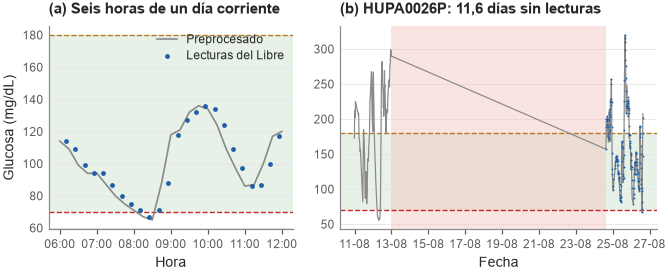

In [6]:
def linear_stretches(pre):
    """Start and end of the longest straight-line stretch of the preprocessed glucose."""
    flat = (pre["glucose"].diff().diff().abs() < 1e-6).to_numpy()
    runs = hupa._runs(flat)
    a, b = max(runs, key=lambda r: r[1] - r[0])
    return pre["time"].iloc[a - 1], pre["time"].iloc[b + 1]

patient = "HUPA0026P"
pre = hupa.read_preprocessed(patient)
raw = hupa.libre_glucose(patient, (pre["time"].min(), pre["time"].max()))
gap_start, gap_end = linear_stretches(pre)

fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH_FULL, 2.7), gridspec_kw={"width_ratios": [1, 1.3]})

# (a) six hours of an ordinary day: the preprocessed lattice is not the readings.
t0 = pd.Timestamp("2020-06-01 06:00")
t1 = t0 + pd.Timedelta(hours=6)
m_pre = pre["time"].between(t0, t1)
m_raw = raw["ts"].between(t0, t1)
ax = axes[0]
ax.plot(pre.loc[m_pre, "time"], pre.loc[m_pre, "glucose"], lw=1.1, color=INK["tenue"],
        label="Preprocesado")
ax.scatter(raw.loc[m_raw, "ts"], raw.loc[m_raw, "value"], s=10, color=HUPA_COLOR, zorder=3,
           label="Lecturas del Libre")
add_glycemic_bands(ax, show_severe=False)
ax.set_title("(a) Seis horas de un día corriente")
ax.set_xlabel("Hora")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
ax.legend(loc="upper right")

# (b) the longest interpolated stretch: days of straight line with no reading.
pad = pd.Timedelta(days=2)
m_pre = pre["time"].between(gap_start - pad, gap_end + pad)
m_raw = raw["ts"].between(gap_start - pad, gap_end + pad)
ax = axes[1]
ax.axvspan(gap_start, gap_end, color=ROLE["hipo_relleno"], alpha=0.45, lw=0)
ax.plot(pre.loc[m_pre, "time"], pre.loc[m_pre, "glucose"], lw=0.8, color=INK["tenue"])
ax.scatter(raw.loc[m_raw, "ts"], raw.loc[m_raw, "value"], s=1.5, color=HUPA_COLOR, zorder=3)
add_glycemic_bands(ax, show_severe=False)
ax.set_ylabel("")
days = (gap_end - gap_start).total_seconds() / 86400
ax.set_title(f"(b) {patient}: {days:.1f} días sin lecturas".replace(".", ",", 1))
ax.set_xlabel("Fecha")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d-%m"))
fig.tight_layout()
save_figure(fig, "07_hupa_preprocesado")
print(f"Hueco: {gap_start} -> {gap_end} ({days:.1f} días)")

**Figura 07_hupa_preprocesado.** (a) Seis horas de un día corriente: la curva del preprocesado
va desfasada respecto a las lecturas del Libre y se separa de ellas en los cambios rápidos (la
subida de las 09:00). Usarla como objetivo sería evaluar el modelo contra una interpolación.
(b) El hueco más largo de HUPA0026P (sombreado): 11,6 días sin una sola lectura, rellenados con una recta
de 290 a 158 mg/dL que cruza el rango objetivo como si fuera glucosa.

## 3. HUPA frente a Ohio: glucemia e hipoglucemia

In [7]:
# OhioT1DM: solo el train, como en el resto del EDA (el test se reserva para la evaluación).
ohio_rows, ohio_values, ohio_hours = [], [], []
for p in OHIO_PATIENTS:
    cgm = load_cgm(p, "train")
    ev = q.glycemic_events(cgm)
    days = (cgm["ts"].iloc[-1] - cgm["ts"].iloc[0]).total_seconds() / 86400
    v = cgm["value"]
    ohio_rows.append({"patient": p, "dataset": "OhioT1DM", "days": days,
                      "pct_below_70": 100 * (v < q.HYPO).mean(),
                      "pct_70_180": 100 * v.between(q.TARGET_LOW, q.TARGET_HIGH).mean(),
                      "events_per_day": len(ev) / days})
    ohio_values.append(v.to_numpy())
    ohio_hours.append(ev["hour"].to_numpy())

hupa_rows, hupa_values, hupa_hours = [], [], []
for p, fr in frames.items():
    ev = hupa.libre_events(fr)
    v = fr.loc[fr["is_reading"], "value"]
    days = (fr["ts"].iloc[-1] - fr["ts"].iloc[0]).total_seconds() / 86400
    hupa_rows.append({"patient": p, "dataset": "HUPA-UCM", "record_tier": hupa.RECORD_TIER[p],
                      "days": days, "pct_below_70": 100 * (v < q.HYPO).mean(),
                      "pct_70_180": 100 * v.between(q.TARGET_LOW, q.TARGET_HIGH).mean(),
                      "events_per_day": len(ev) / days})
    hupa_values.append(v.to_numpy())
    hupa_hours.append(ev["hour"].to_numpy())

per_patient = pd.concat([pd.DataFrame(ohio_rows), pd.DataFrame(hupa_rows)], ignore_index=True)
per_patient.groupby("dataset")[["pct_below_70", "pct_70_180", "events_per_day"]].describe(
    percentiles=[0.5]).round(2).T

dataset               HUPA-UCM  OhioT1DM
pct_below_70   count     23.00     12.00
               mean       7.89      3.42
               std        5.75      2.39
               min        2.19      0.88
               50%        6.17      2.86
               max       23.88      8.13
pct_70_180     count     23.00     12.00
               mean      61.43     63.80
               std       14.55     10.26
               min       36.33     43.15
               50%       58.07     64.12
               max       92.91     74.22
events_per_day count     23.00     12.00
               mean       1.12      0.78
               std        0.54      0.42
               min        0.43      0.30
               50%        1.01      0.72
               max        2.41      1.52

In [8]:
ohio_all, hupa_all = np.concatenate(ohio_values), np.concatenate(hupa_values)
pooled = pd.DataFrame({
    "OhioT1DM (train)": [len(ohio_all), 100 * (ohio_all < 54).mean(), 100 * (ohio_all < 70).mean(),
                         100 * ((ohio_all >= 70) & (ohio_all <= 180)).mean(), 100 * (ohio_all > 250).mean(),
                         np.mean(ohio_all), np.std(ohio_all)],
    "HUPA-UCM": [len(hupa_all), 100 * (hupa_all < 54).mean(), 100 * (hupa_all < 70).mean(),
                 100 * ((hupa_all >= 70) & (hupa_all <= 180)).mean(), 100 * (hupa_all > 250).mean(),
                 np.mean(hupa_all), np.std(hupa_all)],
}, index=["lecturas", "% < 54", "% < 70", "% 70-180", "% > 250", "media (mg/dL)", "DE (mg/dL)"])
pooled.round(2)

,OhioT1DM (train),HUPA-UCM
lecturas,134790.00,91106.00
% < 54,0.77,1.57
% < 70,3.41,6.76
% 70-180,63.73,72.73
% > 250,8.14,4.81
media (mg/dL),158.95,139.44
DE (mg/dL),60.72,56.84


**HUPA pasa el doble de tiempo en hipoglucemia que Ohio**: el 6,76 % de las lecturas está por
debajo de 70 mg/dL, frente al 3,41 %, y el 1,57 % por debajo de 54, frente al 0,77 %. A la vez
tiene menos hiperglucemia (4,81 % > 250 frente a 8,14 %), más tiempo en rango (72,7 % frente a
63,7 %) y una media de 139 mg/dL frente a 159. Es una población mejor controlada y más
hipoglucémica: hay más eventos que detectar, y el modelo recibe una distribución desplazada
hacia abajo.

Dos cautelas. La primera: el agregado de HUPA está dominado por HUPA0027P (51.581 de las
91.106 lecturas), así que la comparación justa es la de las medianas por paciente, debajo. La
segunda: parte de la diferencia puede ser del sensor (Libre frente a Enlite) y no de los
pacientes [CITA PENDIENTE: exactitud del FreeStyle Libre en el rango hipoglucémico].

pct_below_70: Ohio mediana 2.86 (máx 8.13); HUPA mediana 6.17; pacientes HUPA por encima del máximo de Ohio: 9 de 23
events_per_day: Ohio mediana 0.72 (máx 1.52); HUPA mediana 1.01; pacientes HUPA por encima del máximo de Ohio: 5 de 23


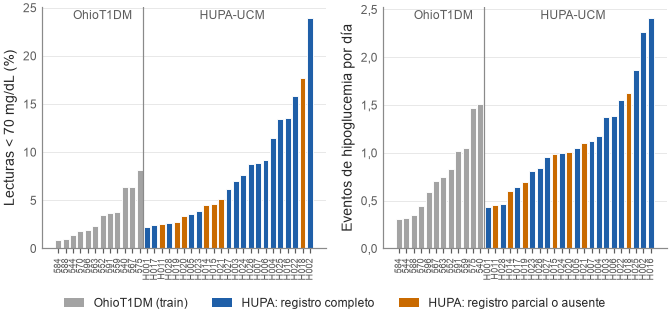

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH_FULL, 3.0), sharey=False)
for ax, col, label in ((axes[0], "pct_below_70", "Lecturas < 70 mg/dL (%)"),
                       (axes[1], "events_per_day", "Eventos de hipoglucemia por día")):
    d = per_patient.sort_values(["dataset", col], ascending=[False, True]).reset_index(drop=True)
    colors = [OHIO_COLOR if ds == "OhioT1DM" else TIER_COLORS[t]
              for ds, t in zip(d["dataset"], d["record_tier"])]
    ax.bar(range(len(d)), d[col], color=colors, width=0.8, edgecolor="white", linewidth=0.6)
    ax.set_xticks(range(len(d)))
    ax.set_xticklabels(d["patient"].str.replace("HUPA0", "H").str.replace("P", ""),
                       rotation=90, fontsize=6)
    ax.set_ylabel(label)
    n_ohio = (d["dataset"] == "OhioT1DM").sum()
    ax.axvline(n_ohio - 0.5, color=INK["tenue"], lw=0.8)
    ax.text(n_ohio / 2, ax.get_ylim()[1] * 0.95, "OhioT1DM", ha="center", fontsize=8,
            color=INK["secundario"])
    ax.text(n_ohio + (len(d) - n_ohio) / 2, ax.get_ylim()[1] * 0.95, "HUPA-UCM", ha="center",
            fontsize=8, color=INK["secundario"])
handles = [plt.Rectangle((0, 0), 1, 1, color=c)
           for c in (OHIO_COLOR, TIER_COLORS["completo"], TIER_COLORS["parcial"])]
fig.legend(handles, ["OhioT1DM (train)", "HUPA: registro completo",
                     "HUPA: registro parcial o ausente"], loc="lower center", ncol=3)
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(fig, "07_hupa_vs_ohio_hipo")

o = per_patient.query("dataset == 'OhioT1DM'")
h = per_patient.query("dataset == 'HUPA-UCM'")
for col in ("pct_below_70", "events_per_day"):
    print(f"{col}: Ohio mediana {o[col].median():.2f} (máx {o[col].max():.2f}); "
          f"HUPA mediana {h[col].median():.2f}; pacientes HUPA por encima del máximo de Ohio: "
          f"{(h[col] > o[col].max()).sum()} de {len(h)}")

**Figura 07_hupa_vs_ohio_hipo.** Por paciente, la diferencia se mantiene: la mediana de lecturas
< 70 es del 6,2 % en HUPA frente al 2,9 % en Ohio, y **9 de los 23 pacientes de HUPA están por
encima del paciente más hipoglucémico de Ohio** (575, 8,1 %). En eventos por día la diferencia es
menor (mediana 1,01 frente a 0,72), porque en HUPA abundan los episodios cortos.

Las dos definiciones de evento son equivalentes en duración (≥ 15 min por debajo de 70), pero no
idénticas: en Ohio son 3 muestras de 5 min y en HUPA 2 lecturas de 15 min.

Eventos que empiezan entre 00:00 y 05:59 -> Ohio 20.5 %, HUPA 21.9 %


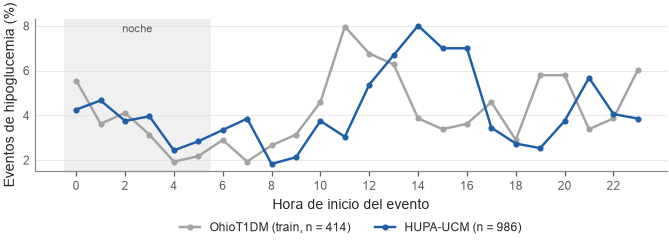

In [10]:
def hourly_share(hours):
    h = np.concatenate(hours)
    return pd.Series(np.bincount(h, minlength=24) / len(h) * 100)

night = lambda s: s.loc[0:5].sum()
oh, hu = hourly_share(ohio_hours), hourly_share(hupa_hours)
fig, ax = plt.subplots(figsize=(FIG_WIDTH_FULL, 2.4))
ax.axvspan(-0.5, 5.5, color=INK["rejilla"], alpha=0.6, lw=0)
ax.plot(oh.index, oh.values, marker="o", ms=3, color=OHIO_COLOR, label=f"OhioT1DM (train, n = {sum(map(len, ohio_hours))})")
ax.plot(hu.index, hu.values, marker="o", ms=3, color=HUPA_COLOR, label=f"HUPA-UCM (n = {sum(map(len, hupa_hours))})")
ax.text(2.5, ax.get_ylim()[1] * 0.97, "noche", ha="center", va="top", fontsize=7, color=INK["secundario"])
ax.set_xlabel("Hora de inicio del evento")
ax.set_ylabel("Eventos de hipoglucemia (%)")
ax.set_xticks(range(0, 24, 2))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)
fig.tight_layout()
save_figure(fig, "07_hupa_hipo_por_hora")
print(f"Eventos que empiezan entre 00:00 y 05:59 -> Ohio {night(oh):.1f} %, HUPA {night(hu):.1f} %")

**Figura 07_hupa_hipo_por_hora.** El peso de la noche es el mismo en las dos cohortes (el 20,5 %
de los eventos empieza entre las 00:00 y las 05:59 en Ohio y el 21,9 % en HUPA). Lo que cambia
es el pico diurno: en Ohio está a las 11 h y en HUPA entre las 12 y las 16 h. Es compatible con
el horario de comidas español, más tardío, pero es una hipótesis, no algo que estos datos
demuestren. Importa porque el modelo recibe la hora (`hour_sin`, `hour_cos`) y aprendió el ritmo
de Ohio.

## 4. Desplazamiento de las entradas del modelo

In [11]:
def last_step(ws_list):
    return np.concatenate([w.X[:, -1, :] for w in ws_list if len(w)])

ohio_X = last_step([load_processed(p, "train") for p in OHIO_PATIENTS])
hupa_ws = {p: hupa.patient_windows(fr) for p, fr in frames.items()}
hupa_X = last_step(hupa_ws.values())
hupa_X_full = last_step([w for p, w in hupa_ws.items() if hupa.RECORD_TIER[p] == "completo"])

shift = pd.DataFrame({
    "Ohio media": ohio_X.mean(0), "HUPA media": hupa_X.mean(0),
    "HUPA completo media": hupa_X_full.mean(0),
    "Ohio DE": ohio_X.std(0), "HUPA DE": hupa_X.std(0),
}, index=FEATURE_COLUMNS)
# Standardised mean difference in Ohio units: what the Ohio scaler will make of HUPA.
shift["desplaz. (DE de Ohio)"] = (shift["HUPA completo media"] - shift["Ohio media"]) / shift["Ohio DE"]
shift.round(3)

,Ohio media,HUPA media,HUPA completo media,Ohio DE,HUPA DE,desplaz. (DE de Ohio)
value,158.636002,139.330002,137.052994,60.195000,56.507999,-0.359
roc,-0.002000,0.005000,0.006000,0.978000,0.769000,0.008
iob,2.652000,1.619000,1.749000,3.919000,2.843000,-0.230
bolus_dose,0.113000,0.072000,0.077000,0.963000,0.798000,-0.037
basal_rate,0.994000,0.520000,0.544000,0.420000,0.428000,-1.072
pump_suspended,0.021000,0.002000,0.003000,0.145000,0.049000,-0.130
cob,9.999000,5.919000,6.274000,20.165001,13.686000,-0.185
carbs,0.527000,0.348000,0.369000,6.136000,4.292000,-0.026
hour_sin,-0.012000,0.003000,0.005000,0.705000,0.722000,0.025
hour_cos,0.018000,-0.031000,-0.035000,0.709000,0.691000,-0.074


La última columna expresa la diferencia de medias en desviaciones típicas de Ohio, que es lo
que verá el modelo tras aplicar el escalador de Ohio. **El desplazamiento grande es la basal
(−1,07 DE)**: en HUPA la media es 0,54 U/h frente a 0,99. Influyen las plumas (la insulina lenta
repartida en 24 h) y que las dosis sean menores en general. Le siguen la glucosa (−0,36), el IOB
(−0,23) y el COB (−0,19); el resto queda por debajo de 0,15. `is_imputed` vale casi siempre 0
porque solo marca los huecos que exceden la cadencia del Libre (modo `dropouts`), que es su
significado en Ohio.

Para la Fase 8A.3, la basal es la primera candidata a explicar una degradación, y el subgrupo
CSII/MDI la separa directamente.

[PosixPath('memoria/figuras/07_hupa_desplazamiento.pdf'),
 PosixPath('memoria/figuras/07_hupa_desplazamiento.png')]

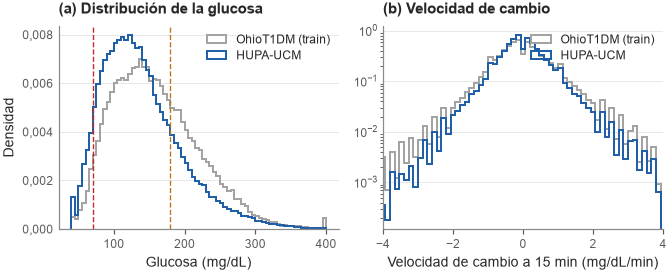

In [12]:
roc = FEATURE_COLUMNS.index("roc")
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH_FULL, 2.7))
bins = np.linspace(40, 400, 73)
axes[0].hist(ohio_all, bins=bins, density=True, histtype="step", lw=1.3, color=OHIO_COLOR, label="OhioT1DM (train)")
axes[0].hist(hupa_all, bins=bins, density=True, histtype="step", lw=1.3, color=HUPA_COLOR, label="HUPA-UCM")
axes[0].axvline(70, color=ROLE["hipo"], ls="--", lw=0.9)
axes[0].axvline(180, color=ROLE["hiper"], ls="--", lw=0.9)
axes[0].set_xlabel("Glucosa (mg/dL)")
axes[0].set_ylabel("Densidad")
axes[0].set_title("(a) Distribución de la glucosa")
axes[0].legend()
# The ROC takes only multiples of 1/15 (integer mg/dL over 15 min): bins must follow that
# lattice or the histogram shows a comb that is an artefact, not the data.
rb = (np.arange(-60, 62, 2) - 1) / 15
axes[1].hist(ohio_X[:, roc], bins=rb, density=True, histtype="step", lw=1.3, color=OHIO_COLOR, label="OhioT1DM (train)")
axes[1].hist(hupa_X[:, roc], bins=rb, density=True, histtype="step", lw=1.3, color=HUPA_COLOR, label="HUPA-UCM")
axes[1].set_xlim(-4, 4)
axes[1].set_xlabel("Velocidad de cambio a 15 min (mg/dL/min)")
axes[1].set_title("(b) Velocidad de cambio")
axes[1].set_yscale("log")
axes[1].legend(loc="upper right")
fig.tight_layout()
save_figure(fig, "07_hupa_desplazamiento")

**Figura 07_hupa_desplazamiento.** (a) La glucosa de HUPA tiene el máximo hacia 120 mg/dL, frente
a unos 140 en Ohio, y una cola alta más ligera. Cada sensor acumula lecturas en un extremo: Ohio
en 400 mg/dL (el techo de registro del Enlite) y HUPA en el intervalo más bajo, junto a
40 mg/dL. (b) La velocidad de cambio de HUPA tiene las colas más ligeras (DE 0,77 frente a
0,98 mg/dL/min): el Libre registra cada 15 min una señal más suavizada, así que los cambios
bruscos que el modelo aprendió a usar en Ohio son más raros.

## 5. Split y presupuesto de eventos

In [13]:
budget = hupa.event_budget(frames)
budget["largo"] = budget["days"] > 30
tab = budget.groupby(["record_tier", "largo"]).agg(
    pacientes=("patient", "size"), eventos_serie=("events_all", "sum"),
    eventos_test=("events_test", "sum"))
print(tab)
short_full = budget.query("record_tier == 'completo' and not largo")
print(f"\nCompleto y corto: {len(short_full)} pacientes, {short_full.events_all.sum()} eventos en la serie "
      f"y {short_full.events_test.sum()} en el último {hupa.TEST_FRACTION:.0%}")
print(f"Pacientes con < 5 eventos en el test: "
      f"{', '.join(short_full.query('events_test < 5').patient)}")

                    pacientes  eventos_serie  eventos_test
record_tier  largo                                        
completo     False         13            210            61
             True           3            699           216
parcial      False          5             42            15
sin_registro False          2             35            11

Completo y corto: 13 pacientes, 210 eventos en la serie y 61 en el último 30%
Pacientes con < 5 eventos en el test: HUPA0001P, HUPA0004P, HUPA0005P, HUPA0006P, HUPA0007P, HUPA0017P, HUPA0023P, HUPA0024P


**Split**: el último 30 % de las lecturas de cada paciente es el test (`hupa.split_frame`). El 70 %
inicial queda para la adaptación de la Fase 8A.4. El modelo sin reentrenar no ha visto HUPA, así
que se puede evaluar en la serie entera. El test existe para comparar ese modelo con los
adaptados exactamente sobre los mismos puntos.

**Presupuesto**: los 13 pacientes cortos con registro completo tienen **210 eventos en toda la
serie y 61 en el test**, los mismos 61 que puntúan en el test oficial de Ohio (coincidencia).
**8 de esos 13 tienen menos de 5 eventos en el test**, así que rigen las mismas reglas que en
Ohio: recall agregado por eventos con IC bootstrap y sin interpretar el recall individual.

Propuesta para la Fase 8A.3:

- **Cifra principal**: la evaluación sin reentrenar (E1, E2) sobre la serie entera de los 13
  pacientes cortos con registro completo (210 eventos, 3,4 veces Ohio).
- **Comparación con la adaptación**: la misma evaluación restringida al test (61 eventos).
- **Por separado**: los 3 pacientes largos (699 eventos), y los grupos `parcial` y
  `sin_registro` como subgrupos.

In [14]:
rows = []
for p, fr in frames.items():
    parts = hupa.split_frame(fr)
    for name, part in parts.items():
        ws = hupa.patient_windows(part)
        rows.append({"patient": p, "parte": name, "ventanas": len(ws),
                     "pct_hipo_30": round(100 * float((ws.y[:, 0] < q.HYPO).mean()), 2) if len(ws) else np.nan,
                     "dias": round((part["ts"].iloc[-1] - part["ts"].iloc[0]).total_seconds() / 86400, 1)})
win = pd.DataFrame(rows).pivot(index="patient", columns="parte", values=["ventanas", "dias", "pct_hipo_30"])
print(f"Ventanas: adaptación {int(win['ventanas']['adapt'].sum()):,}  test {int(win['ventanas']['test'].sum()):,}")
win.head(8)

Ventanas: adaptación 57,618  test 24,696


ventanas         dias      pct_hipo_30       
parte        adapt   test adapt test       adapt   test
patient                                                
HUPA0001P    866.0  365.0   9.7  4.2        1.73   2.19
HUPA0002P    668.0  286.0   7.7  3.3       23.20  28.32
HUPA0003P    816.0  348.0   9.2  3.9        3.55  12.36
HUPA0004P    572.0  231.0   7.0  4.0       10.49  12.12
HUPA0005P    826.0  355.0   9.3  4.0        4.36   1.13
HUPA0006P    467.0  183.0   5.4  2.5       11.78   5.46
HUPA0007P    831.0  353.0   9.3  4.0        8.66   8.78
HUPA0011P    849.0  368.0   9.3  4.0        2.12   3.26

In [15]:
short = budget.query("not largo").patient
adapt_days = win["dias"]["adapt"].loc[short]
print(f"Días disponibles para adaptar (pacientes cortos): mínimo {adapt_days.min()}, "
      f"mediana {adapt_days.median()}, máximo {adapt_days.max()}")
print("Pacientes con ≥ 7 días de adaptación:", int((adapt_days >= 7).sum()), "de", len(adapt_days))

Días disponibles para adaptar (pacientes cortos): mínimo 5.4, mediana 9.1, máximo 9.7
Pacientes con ≥ 7 días de adaptación: 17 de 20


Hay 57.618 ventanas de adaptación y 24.696 de test, ancladas siempre en una lectura real. Los
pacientes cortos tienen entre **5,4 y 9,7 días de adaptación** (mediana 9,1): N = 1 y 3 días
caben en todos, y **N = 7 en 17 de los 20**. La Fase 8A.4 lo declarará así, en vez de rellenar o
excluir en silencio.

## Conclusiones

1. **La glucosa de `Preprocessed/` no se puede usar como objetivo**: no son lecturas (coincide con
   el Libre en un 36 % de los instantes) y rellena huecos de hasta 11,6 días. Se lee el crudo; se
   pierden 79 h y 333 h no verificables de los dos pacientes largos.
2. **HUPA es más hipoglucémica que Ohio** (6,8 % frente a 3,4 % de lecturas < 70; mediana por
   paciente 6,2 % frente a 2,9 %), con más tiempo en rango y glucosa media más baja. Hay más
   eventos que detectar.
3. **El desplazamiento de entradas más grande es la basal** (−1,07 DE de Ohio), seguido de la
   glucosa (−0,36). La velocidad de cambio del Libre es más suave. El subgrupo CSII/MDI y el
   nivel de registro son obligatorios al reportar.
4. **Presupuesto**: 210 eventos en la serie de los 13 pacientes cortos con registro completo
   (cifra principal sin reentrenar) y 61 en su test (comparación con la adaptación). Los 3 largos
   (699) se informan aparte.

**Figuras exportadas**: `07_hupa_preprocesado`, `07_hupa_vs_ohio_hipo`, `07_hupa_hipo_por_hora`,
`07_hupa_desplazamiento`.

**Siguiente**: Fase 8A.3, el ensemble de Ohio evaluado en HUPA sin reentrenar y con el α de Ohio.